# Switching growth conditions

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

import builtins
builtins.NAMING = "new"


from RealTrace_paper_analysis.plotting_src.header_settings import *
from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *

from scipy import stats

# from RealTrace_paper_analysis.plotting_src.plot_correlations_from_npz import *

%config InlineBackend.figure_format ='retina'

header_setting.py: using new naming


In [15]:
input_dir = "../../data_realtrace_paper/switching_condition/output_realtrace/"
prediction_files = get_input_files(input_dir, keyword="prediction.csv")

# # prediction_files = [f for f in prediction_files if "rpsB" not in f]
raw_input_dir = "../../data_realtrace_paper/switching_condition/input_files/"


In [3]:
meta_file = "../../data_realtrace_paper/switching_condition/all_mmexperiments_datalist.csv"

def get_metas(prediction_files, meta_file):
    prediction_files = sorted(prediction_files)
    samples = pd.DataFrame(index=prediction_files, 
                           columns=["date", "sample", "promoter", "condition", "replicate", "switch_frame"])
    
    meta_dat = pd.read_csv(meta_file, dtype=str)
    
    for pf in prediction_files:
        sample = "_".join(pf.split("/")[-1].split(".")[0].split("_")[:4])
        samples.loc[pf,"sample"] = sample
        samples.loc[pf,"condition"] = "_".join(sample.split("_")[0:2])
        samples.loc[pf,"promoter"] = sample.split("_")[3]
        samples.loc[pf,"date"] = sample.split("_")[2]
        
        meta = meta_dat[meta_dat["promoter"] == samples.loc[pf,"promoter"]]
        meta = meta[meta["date"]== samples.loc[pf,"date"]]        
        samples.loc[pf, "switch_frame"] = int(meta[meta["condition"] == "glycerol040"]["f_start"].to_numpy()[0])
        
    return samples.to_dict('index')


samples = get_metas(prediction_files, meta_file)
samples

{'../../data_realtrace_paper/switching_condition/output_realtrace/glucose_glycerol_20190515_hi1_f01234578910_b_f01234578910_b_prediction.csv': {'date': '20190515',
  'sample': 'glucose_glycerol_20190515_hi1',
  'promoter': 'hi1',
  'condition': 'glucose_glycerol',
  'replicate': nan,
  'switch_frame': 440},
 '../../data_realtrace_paper/switching_condition/output_realtrace/glucose_glycerol_20190529_hi3_f01234578910_b_f01234578910_b_prediction.csv': {'date': '20190529',
  'sample': 'glucose_glycerol_20190529_hi3',
  'promoter': 'hi3',
  'condition': 'glucose_glycerol',
  'replicate': nan,
  'switch_frame': 220},
 '../../data_realtrace_paper/switching_condition/output_realtrace/glucose_glycerol_20190529_rplN_f01234578910_b_f01234578910_b_prediction.csv': {'date': '20190529',
  'sample': 'glucose_glycerol_20190529_rplN',
  'promoter': 'rplN',
  'condition': 'glucose_glycerol',
  'replicate': nan,
  'switch_frame': 220},
 '../../data_realtrace_paper/switching_condition/output_realtrace/gluc

In [4]:


def calc_log_concentration(cells):
    for i, cell in enumerate(cells):
        c = cell.gfp/np.exp(cell.log_length)
        if np.any(c<0):
            print(c)
        cells[i].log_concentration = np.log(c)
        cells[i].log1_concentration = np.log(c+1)
        cells[i].concentration = c
    return cells


def get_integration_file(pf, setting):
    parent_dir = os.path.join(*pf.split("/")[:-1])
    sample = '_'.join(pf.split('/')[-1].split('_')[:3])
    return os.path.join(parent_dir, "integration",sample, setting, sample+"_"+setting+'.csv')


def calc_mean(means, covs=None):
    if np.any(covs==None):
        mean = np.mean(means)
    else:
        mean = np.sum(means/covs) /np.sum(1/covs)
    return mean

def calc_cv(means, covs=None):
    if np.any(covs==None):
        return np.std(means)/np.mean(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)/calc_mean(means)

def calc_std(means, covs=None):
    if np.any(covs==None):
        return np.std(means)
    else:
        return np.sqrt(np.sum(np.power(means, 2) + covs)/len(means) - np.mean(means)**2)

def fetch_raw_file(prediction_filename, raw_input_dir):
    entries = os.listdir(raw_input_dir)
    for e in entries:
        sample = '_'.join(prediction_filename.split('/')[-1].split('_f')[:1]) +".csv"
        if sample in e:
            return os.path.join(raw_input_dir,e)
        

def fetch_end_type(cell_id, raw_data_pd, cell_id_col="cell_id", col="end_type"):
    return raw_data_pd[raw_data_pd[cell_id_col]==cell_id][col].to_numpy()[0]
    
def fetch_genealogy(cell_id, raw_data_pd, cell_id_col="cell_id", col="genealogy"):
    return raw_data_pd[raw_data_pd[cell_id_col]==cell_id][col].to_numpy()[0]

def fetch_cell_meta(cell, raw_data_pd):
    cell_id = cell.cell_id
    cell.end_type = raw_data_pd[raw_data_pd["cell_id"]==cell_id]["end_type"].to_numpy()[0]
    cell.genealogy = raw_data_pd[raw_data_pd["cell_id"]==cell_id]["genealogy"].to_numpy()[0]
    cell.last_cell_rank = raw_data_pd[raw_data_pd["cell_id"]==cell_id]["cell_rank"].to_numpy()[-1]
    cell.first_cell_rank = raw_data_pd[raw_data_pd["cell_id"]==cell_id]["cell_rank"].to_numpy()[0]
    return cell

def assign_end_type_to_cells(cells, raw_file, cell_id_col="cell_id", col="end_type"):    
    raw_data_pd = pd.read_csv(raw_file, dtype=str)
    raw_data_pd["cell_id"] = raw_data_pd["full_cell_id"]
    for i, cell in enumerate(cells):
        cells[i] = fetch_cell_meta(cell, raw_data_pd)
    return cells

def shift_time(cells, dt):
    for i, cell in enumerate(cells):
        cells[i].real_time = cell.time
        cells[i].time = cell.time - dt        
    return cells

def get_cells(samples, raw_input_dir=None):
    for pf in samples.keys():

        samples[pf]["parameters"]  = read_header(pf)
        # cells = calc_log_concentration(ggp_df2cells(read_ggp_csv(pf)))
        cells = calc_log_concentration(df2ggp_cells(read_ggp_csv(pf)))
        cells = shift_time(cells, samples[pf]["switch_frame"]*3)
        
        if raw_input_dir!=None:
            cells = assign_end_type_to_cells(cells, fetch_raw_file(pf, raw_input_dir))
        samples[pf]["ggp_cells"] = cells
    
    for i in ["l", "q"]:
            zi = "mean_{:s}".format(i)
            zi_cov = "cov_{:s}{:s}".format(i, i)

            zi_coll_prediction = np.concatenate([cell.__dict__[zi] for cell in samples[pf]["ggp_cells"]])
            zi_coll_prediction_err = np.concatenate([cell.__dict__[zi_cov] for cell in samples[pf]["ggp_cells"]])
            samples[pf]["{:s}_mean".format(i)] = calc_mean(zi_coll_prediction, zi_coll_prediction_err)
            samples[pf]["{:s}_cv".format(i)] = calc_cv(zi_coll_prediction, zi_coll_prediction_err)
            samples[pf]["{:s}_std".format(i)] = calc_std(zi_coll_prediction, zi_coll_prediction_err)

    return samples
        


def get_corr_func(samples):
    for pf in samples.keys():
        cf = pf.replace("_autofl_corrected_", "_rawdata_")
        cf = cf.replace("_autofl_corrected", "")
        cf = cf.replace("prediction.csv", "correlations.npz")
        data = np.load(cf, allow_pickle=True)
        samples[pf]["correlation_function"] = Correlation_function(data['correlations'])
    return samples
    
    
def filter_dict(samples, filter_key=None):
    new_samples = {}
    for pf in samples.keys():
        sample_name = pf.split("/")[-1].split("_")
        if filter_key in sample_name:
            new_samples[pf] = samples[pf]
    return new_samples

def filter_dict_not(samples, *filter_keys):
    new_samples = {}
    for pf in samples.keys():
        sample_name = pf.split("/")[-1].split("_")
        remove = np.any([filter_key in sample_name for filter_key in filter_keys])
        if not remove:
            new_samples[pf] = samples[pf]
    return new_samples

def get_replicate(samples, repl="1"):
    new_samples = {}
    for pf in samples.keys():
        
        if samples[pf]["replicate"] == repl :
            new_samples[pf] = samples[pf]
    return new_samples


# samples = get_corr_func(samples)
samples = get_cells(samples, raw_input_dir)



In [5]:

def get_long_distinct_paths(cells, n=5):
    temp_cells = copy.deepcopy(cells)
    paths = []
    while len(temp_cells)>0 and n>0:
        longest_path = get_longest_path(temp_cells)
        paths.append(longest_path)
        temp_cells = [cell for i,cell in enumerate(temp_cells) if i not in longest_path]
        print(len(temp_cells), n)
        n=n-1
    return paths



In [6]:
altcolor_by_condition = {cond: col for cond,col  in zip(conditions, ["#101518", "#5e798f", "#95a9ba", "#adbdc9" ])}
altcolor_by_promoter = {p: col for p,col  in zip(['hi1','hi3','rplN','rrnB'], 
                                                 ["#217821" ,"#37c837" ,
                                                  "#951b1c" ,"#db3b3c"])}

In [7]:
sample_key = list(samples.keys())[0]
cells_data = samples[sample_key]["ggp_cells"]
promoter = samples[sample_key]["promoter"]
paths = get_long_distinct_paths(cells_data)

5754 5
5713 4
5672 3
5631 2
5591 1


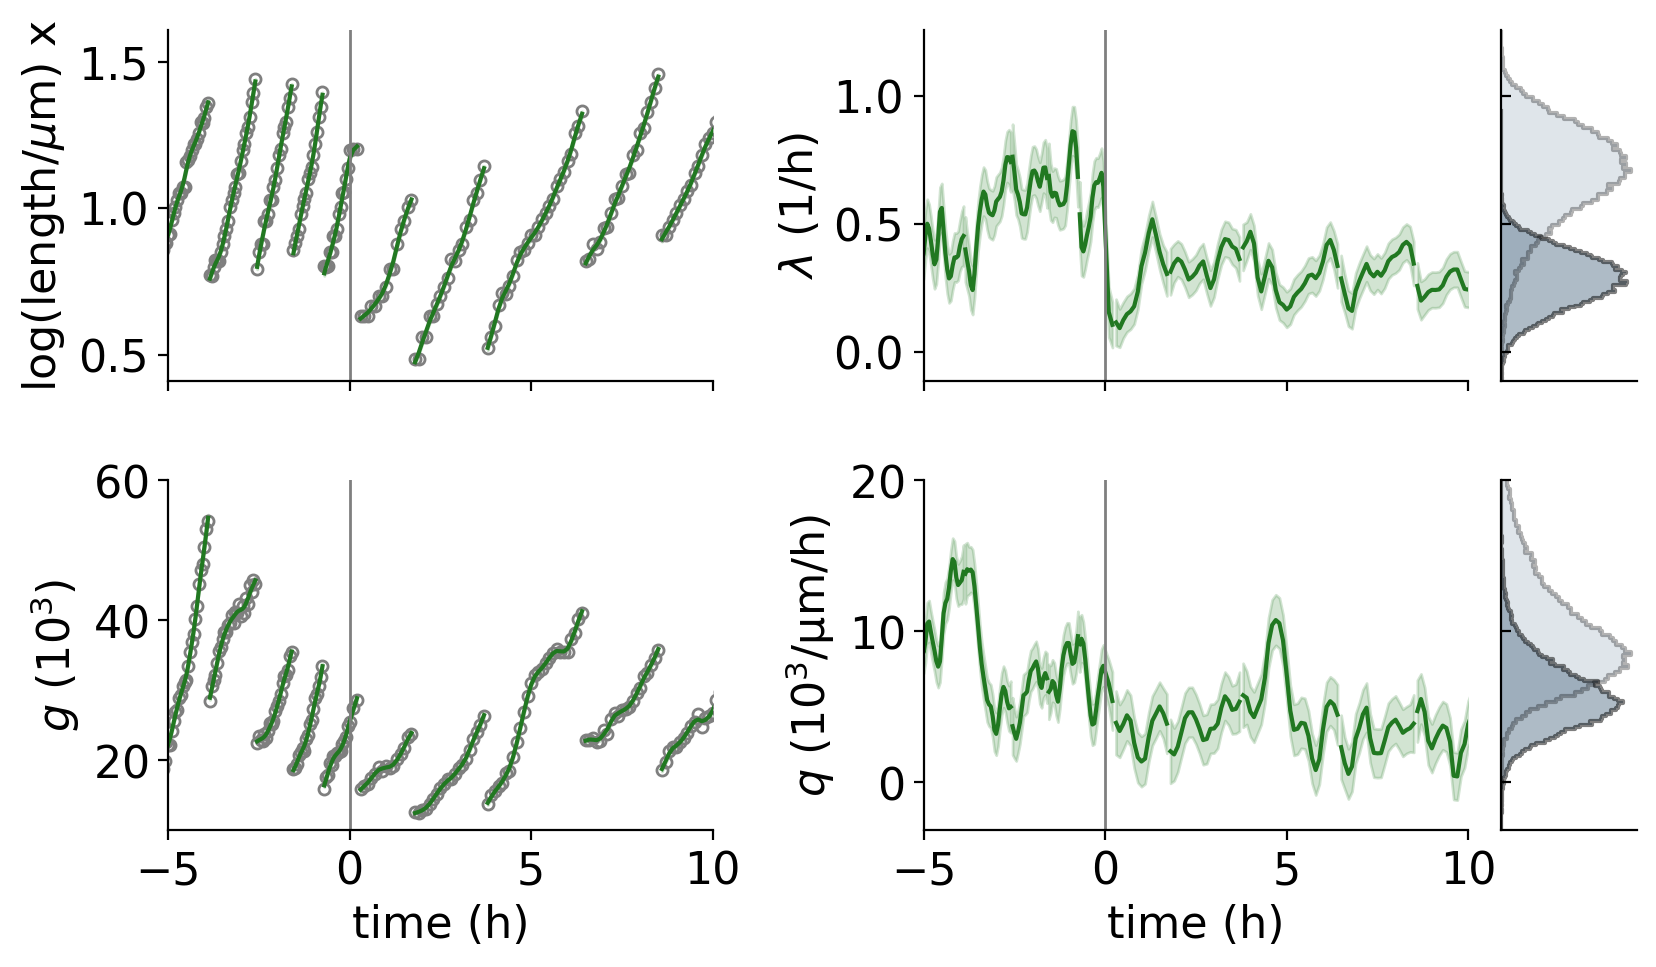

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>],
      dtype=object)

In [8]:

def bin_with_error_bars(means, variances, n_bins=1000, return_edges=True, ignore_errors=False):
    if ignore_errors:
        return np.histogram(means, bins="auto")
    left = np.min(means) - 2*np.sqrt(variances[np.argmin(means)])
    right = np.max(means) + 2*np.sqrt(variances[np.argmax(means)])
    
    _,bin_edges = np.histogram(means, bins=np.linspace(left, right, n_bins))
    
    bin_c = bin_edges[:-1] +np.diff(bin_edges)/2
    weight = np.zeros_like(bin_c)
    for i, m in enumerate(means):
        weight += special.erf( (bin_edges[1:]-m)/np.sqrt(2*variances[i]) ) - special.erf( (bin_edges[:-1]-m)/np.sqrt(2*variances[i]) )
    if return_edges:
        return weight, bin_edges
    else:
        return weight, bin_c
    
def set_size(w,h, ax=None):
    """ w, h: width, height in inches """
    if not ax: ax=plt.gca()
    l = ax.figure.subplotpars.left
    r = ax.figure.subplotpars.right
    t = ax.figure.subplotpars.top
    b = ax.figure.subplotpars.bottom
    figw = float(w)/(r-l)
    figh = float(h)/(t-b)
    ax.figure.set_size_inches(figw, figh)
    
def plot_predictions_cells_carbon_switch(cells, cell_idx, time_unit=("h", 60), 
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=12, 
                           color=["tab:blue"]*100, 
                          ignore_errors=False):
    fig, axes = plt.subplots(2, 2, figsize=(FULL_SIZE*0.7,FULL_HEIGHT), sharex=True)
    axes = axes.transpose()
    ax = axes.ravel()


    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        
    s = 10
    lw = 1.5
    
    mark_transition= mark_transition/ time_unit[1]
    time = np.concatenate([cell.time for cell in cells])/ time_unit[1]
    
    ### LAMBDA
    l_coll = np.concatenate([cell.mean_l for cell in cells])*time_unit[1]
    l_var_coll = np.concatenate([cell.cov_ll for cell in cells])*time_unit[1]**2
    
    
    l_coll_before = l_coll[np.argwhere(time<mark_transition)]
    l_coll_after = l_coll[np.argwhere(time>=mark_transition)]    
    
    l_var_coll_before = l_var_coll[np.argwhere(time<mark_transition)]
    l_var_coll_after = l_var_coll[np.argwhere(time>=mark_transition)]
    
    ### Q
    q_coll = np.concatenate([cell.mean_q for cell in cells])*time_unit[1] /1e3
    q_var_coll = np.concatenate([cell.cov_qq for cell in cells])*time_unit[1]**2 /1e3
    
    
    q_coll_before = q_coll[np.argwhere(time<mark_transition)]
    q_coll_after = q_coll[np.argwhere(time>=mark_transition)]    
    
    q_var_coll_before = q_var_coll[np.argwhere(time<mark_transition)]
    q_var_coll_after = q_var_coll[np.argwhere(time>=mark_transition)]
    
    
    for i, cell in enumerate(cells):
        if i not in cell_idx:
            continue
        time = np.array(cell.time) / time_unit[1]
        prediction_color = color
        rate_color = color
        
        ax[0].plot(time, cell.log_length, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[0].plot(time, cell.mean_x, color=prediction_color, lw=lw)
        ax[0].fill_between(time, cell.mean_x-np.sqrt(cell.cov_xx), cell.mean_x+np.sqrt(cell.cov_xx), 
                    color=prediction_color, alpha=0.2)
        
        
        ax[1].plot(time, cell.gfp/1e3, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[1].plot(time, cell.mean_g/1e3, color=prediction_color, lw=lw)
        ax[1].fill_between(time, 
                           cell.mean_g/1e3-np.sqrt(cell.cov_gg)/1e3, 
                           cell.mean_g/1e3+np.sqrt(cell.cov_gg)/1e3, 
                            color=prediction_color, alpha=0.2)
        
        ax[2].plot(time, 
                   cell.mean_l*time_unit[1], color=rate_color, lw=lw)
        ax[2].fill_between(time, 
                           cell.mean_l*time_unit[1] - np.sqrt(cell.cov_ll)*time_unit[1], 
                           cell.mean_l*time_unit[1] + np.sqrt(cell.cov_ll)*time_unit[1], 
                            color=rate_color, alpha=0.2)

        ax[3].plot(time, 
                   (cell.mean_q*time_unit[1])/1e3,
                   color=rate_color, lw=lw)
        ax[3].fill_between(time, 
                           (cell.mean_q*time_unit[1] - np.sqrt(cell.cov_qq)*time_unit[1])/1e3, 
                           (cell.mean_q*time_unit[1] + np.sqrt(cell.cov_qq)*time_unit[1])/1e3, 
                            color=rate_color, alpha=0.2)

    for i in range(4):
        ax[i].set_xlim(xlim)
        
    # ax[3].set_ylim(-1200, 12000)
    ax2_lim = ax[2].get_ylim()
    ax3_lim = ax[3].get_ylim()
    if mark_transition != None:
        for a in ax:
            # a_ylim = a.get_ylim()
            # a_xlim = a.get_xlim()
            # a.add_patch(plt.Rectangle((0, a_ylim[0]), mark_transition, a_ylim[1]-a_ylim[0], 
            #                           transform=a.transData, 
            #                           color='grey', 
            #                           alpha=0.05))
            # a.add_patch(plt.Rectangle((mark_transition, a_ylim[0]), a_xlim[1]-mark_transition, a_ylim[1]-a_ylim[0], 
            #                           transform=a.transData, 
            #                           color='grey', 
            #                           alpha=0.25))
            a.axvline(0., color="tab:grey", lw=1)


    ax[0].set_ylabel("log(length/$\mu$m) x")  
    ax[1].set_ylabel("$g$ ($10^3$)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(10^3/\mu m/h)}$")   

    # ax[0].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[1].set_xlabel("time ({:s})".format(time_unit[0]))  
    # ax[2].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[3].set_xlabel("time ({:s})".format(time_unit[0]))  
    
    
    ax[1].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)
    ax[3].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)


    #################### HIST

    ax_histy = ax[2].inset_axes([1.06, 0, 0.25, 1], sharey=ax[2])
    ax_histy.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy.set_xlabel("frequency")
    ax_histy.set_xticks([])
        
    hist, bin_edges = bin_with_error_bars(np.ravel(l_coll_before), 
                                          np.ravel(l_var_coll_before), ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color=altcolor_by_condition["glucose020"],
            alpha=0.3)
    ax_histy.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    
    hist, bin_edges = bin_with_error_bars(np.ravel(l_coll_after), 
                                          np.ravel(l_var_coll_after), ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color=altcolor_by_condition["glycerol040"],
            alpha=0.5)
    ax_histy.step(hist, bin_edges[:-1], color="black", alpha=0.5)

    
    ####################
    ax_histy2 = ax[3].inset_axes([1.06, 0, 0.25, 1], sharey=ax[3])
    ax_histy2.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy2.set_xlabel("frequency")
    ax_histy2.set_xticks([])
        
    hist, bin_edges = bin_with_error_bars(np.ravel(q_coll_before), 
                                          np.ravel(q_var_coll_before), ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2
    ax_histy2.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color=altcolor_by_condition["glucose020"],
            alpha=0.3)
    ax_histy2.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    
    hist, bin_edges = bin_with_error_bars(np.ravel(q_coll_after), 
                                          np.ravel(q_var_coll_after), ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2
    ax_histy2.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color=altcolor_by_condition["glycerol040"],
            alpha=0.5)
    ax_histy2.step(hist, bin_edges[:-1], color="black", alpha=0.5)


    ax[1].set_ylim(0.1e2, 0.6e2)
    ax[2].set_ylim(ax2_lim)
    ax[3].set_ylim(ax3_lim[0], 20)
    
    fig.tight_layout()

    
    for a in list(ax) + [ax_histy, ax_histy2]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        set_size(FULL_SIZE*0.5,FULL_HEIGHT, a)

    
    if outfile != None:
        fig.savefig(outfile, bbox_inches='tight')
        plt.show()
        
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax



plot_predictions_cells_carbon_switch(   cells_data, 
                                        paths[1], 
                                        xlim=[-5,10], 
                                        mark_transition=0,
                                        outfile=os.path.join("../../figures_for_method_paper/plots_main/carbon_switch", "sc_traces.pdf"),
                                        color=altcolor_by_promoter[promoter], 
                                        ignore_errors=True)


In [9]:
def sort_samples_by_key(samples, key, sorting):
    new = {}
    for x in sorting:
        for s in samples.keys():
            if samples[s][key] == x:
                new[s] = samples[s]
    return new

samples = sort_samples_by_key(samples, "promoter", ["hi1", "hi3", "rplN", "rrnB" ])

In [10]:
def get_from_all_cells(cells, q, time_window=[None, None]):    
    time = np.concatenate([cell.time/60. for cell in cells])
    
    if q == "l":
        yaxis = np.concatenate([cell.mean_l for cell in cells])*60. # in h
    elif q == "q":
        yaxis = np.concatenate([cell.mean_q for cell in cells])*60. # in h
    elif q == "c":
        yaxis = np.concatenate([cell.concentration for cell in cells])
    elif q == "logc":
        yaxis = np.concatenate([cell.log_concentration for cell in cells])
    elif q == "s":
        yaxis = np.concatenate([np.exp(cell.mean_x) for cell in cells])
    elif q == "n":
        yaxis = np.concatenate([cell.time for cell in cells])
        
    if time_window!=[None, None]:
        yaxis = yaxis[(time>=time_window[0])*(time<=time_window[1])]
        time  =  time[(time>=time_window[0])*(time<=time_window[1])]
        
    return time, yaxis
        

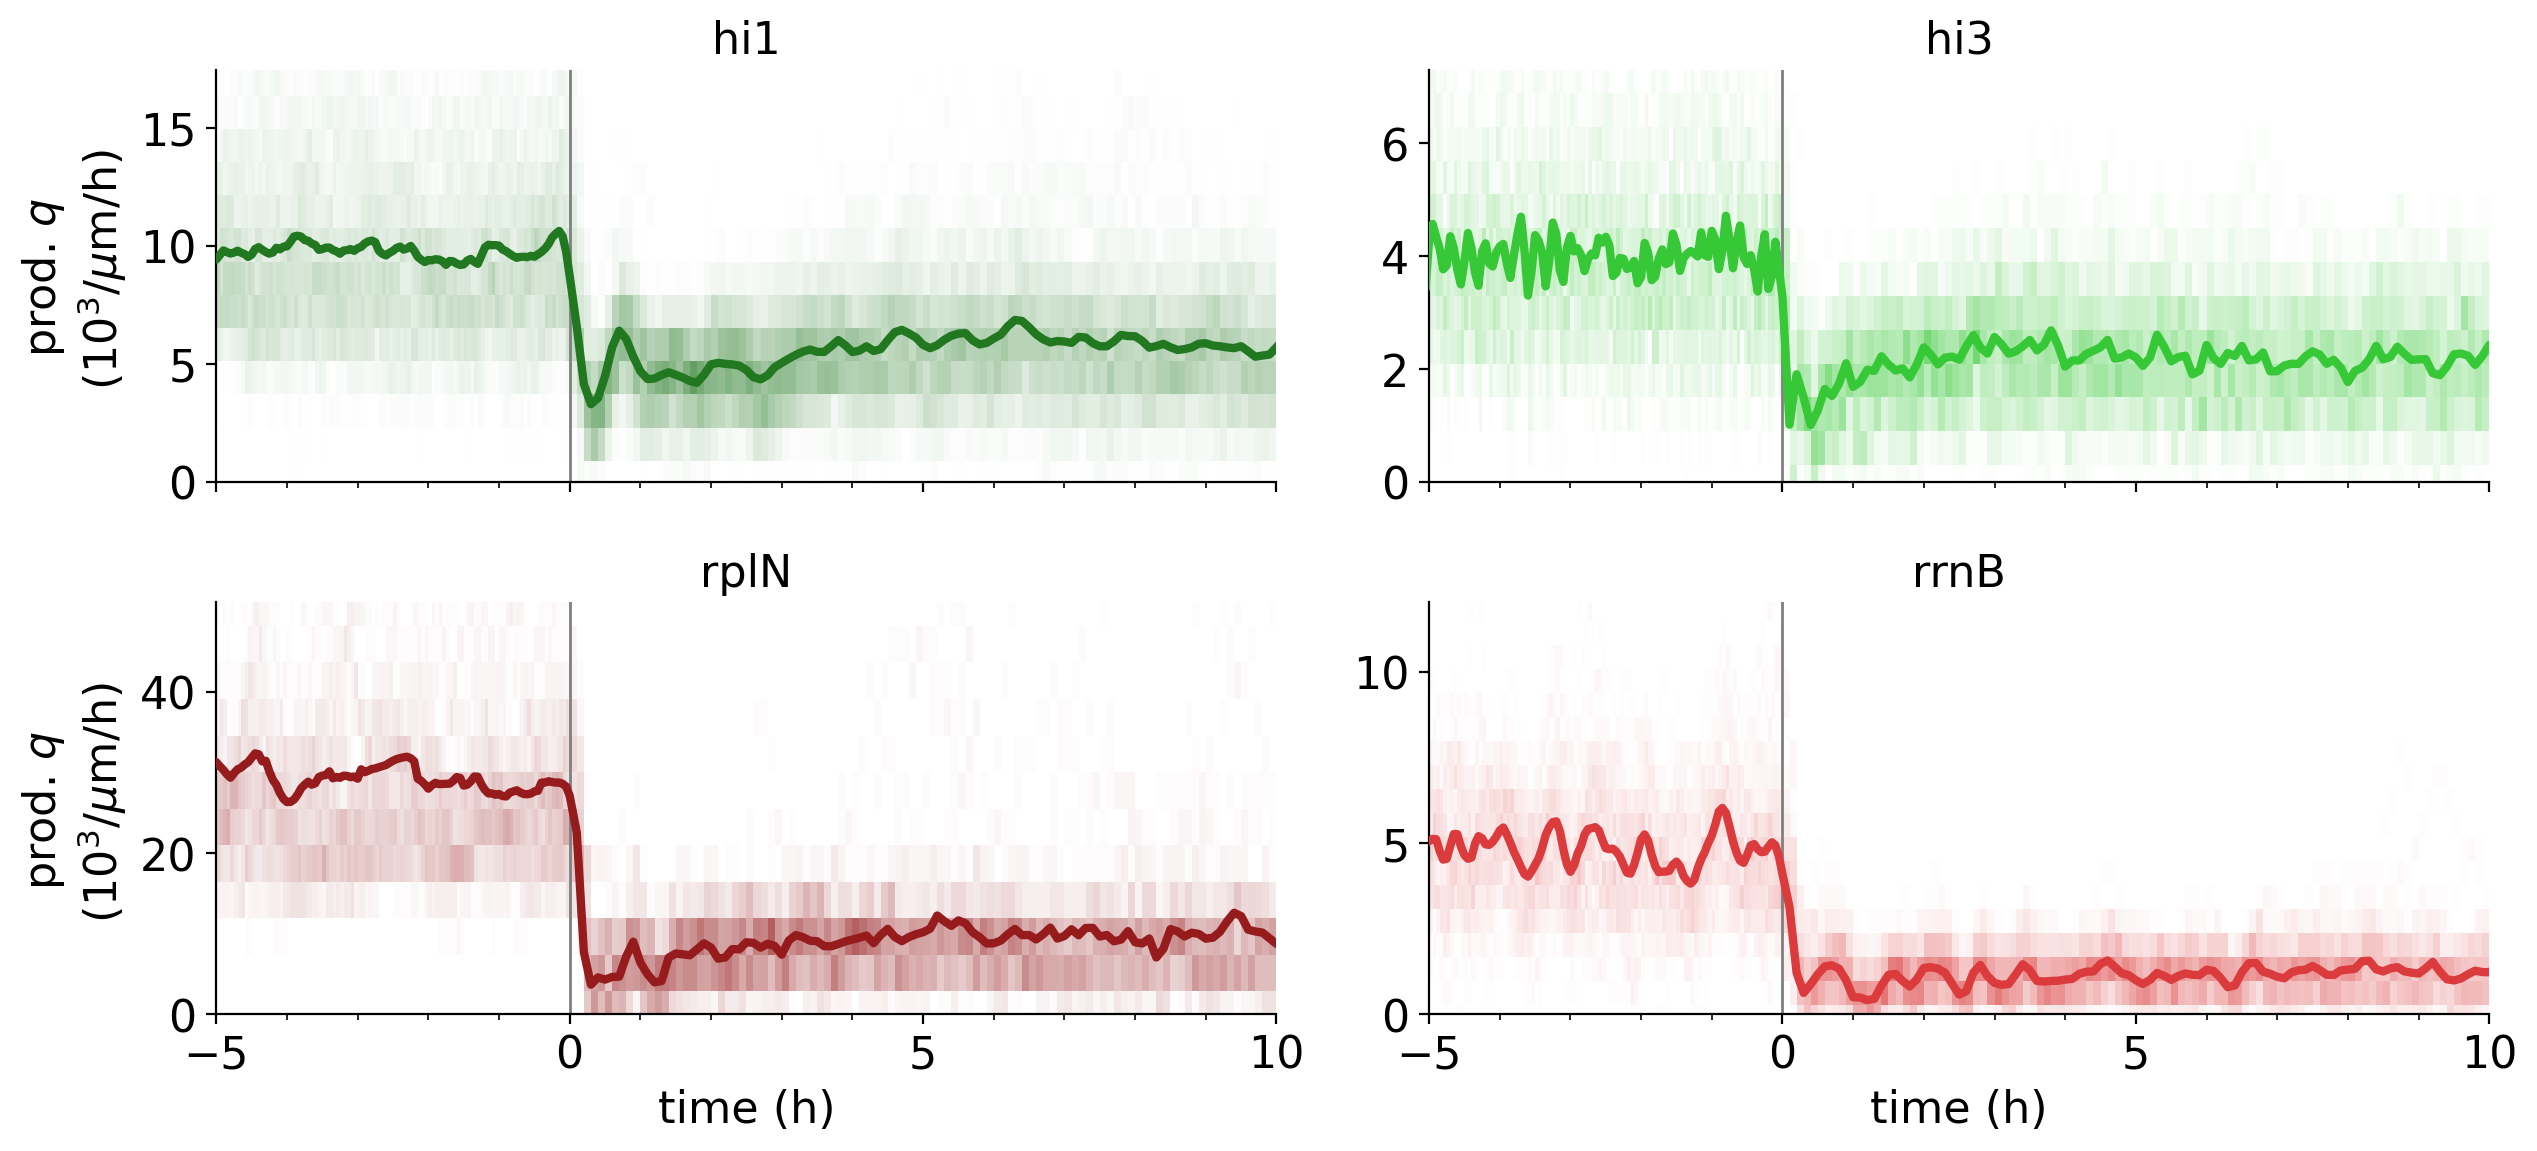

In [11]:

def plot_sc_heatmap(samples, title=None, 
                    rate ='l',
                    plot_file=None, 
                    sharey=False, 
                    ylabel=None):
    
    fig, ax = plt.subplots(2, 2, figsize=(FULL_SIZE,FULL_HEIGHT*1.5), sharex=True, sharey=sharey)
    # fig, ax = plt.subplots(1, 4, figsize=(FULL_SIZE,FULL_HEIGHT), sharex=True, sharey=sharey)
    ax = ax.ravel()
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        

    for j, s in enumerate(samples.keys()):
        cells = samples[s]['ggp_cells']
        promoter = samples[s]['promoter']

        yaxis = get_from_all_cells(cells, rate)[1]/1e3
            
        time = np.concatenate([cell.time/60. for cell in cells])
        
        bins_time = np.unique(time)
        bins_yaxis = np.linspace(np.min(yaxis), np.max(yaxis), 30)

        cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", altcolor_by_promoter[promoter]])
        # cmap = "Greys"
#         if promoter[0]=="r":
#             cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", "tab:red"])
#         else:
#             cmap= matplotlib.colors.LinearSegmentedColormap.from_list("", ["white", "tab:green"])
            
        h = ax[j].hist2d(time, yaxis, cmap=cmap, 
                         bins=[bins_time, bins_yaxis], 
                         density=False, alpha=0.7)
        
        if rate=="c":
            bin_value, bin_edges, binnumber= stats.binned_statistic(time,yaxis, statistic='median', bins=bins_time)
        else:
            bin_value, bin_edges, binnumber= stats.binned_statistic(time,yaxis, statistic='mean', bins=bins_time)
            bin_std, bin_edges, binnumber= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)
        
        # ax[j].plot(bin_edges[:-1], bin_value, color="black", zorder=3, alpha=1, lw=3)  
        ax[j].plot(bin_edges[:-1], bin_value, color=altcolor_by_promoter[promoter], 
                   zorder=3, alpha=1, lw=3)    
        # ax[j].plot(bin_edges[:-1], bin_value, color="white", 
        #            zorder=2.9, alpha=1, lw=6)   
        
        # ax[j].fill_between(bin_edges[:-1], bin_value+bin_std, bin_value-bin_std, 
        #                    color=altcolor_by_promoter[promoter], 
        #                    zorder=3, alpha=0.4)   
        # ax[j].plot(bin_edges[:-1], bin_value, color="grey", zorder=4, alpha=1, lw=3)    
        
        ax[j].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=5))
        ax[j].xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=1))

        ax[j].set_ylim(0, np.max(bin_value)*1.5)
        ax[j].set_title(promoter)
        ax[j].set_xlim(-5,10)
        ax[j].axvline(0., color="tab:grey", lw=1)

    ax[0].set_ylabel(ylabel)
    ax[2].set_ylabel(ylabel)
    
    ax[2].set_xlabel("time (h)")
    ax[3].set_xlabel("time (h)")
    
    plt.tight_layout()
    if plot_file != None: 
        fig.savefig(plot_file, dpi=600, bbox_inches='tight')
    plt.show()
    return fig, ax



fig, ax = plot_sc_heatmap(samples, rate='q', ylabel="prod. $q$ \n ($10^3$/$\mu$m/h)",
                          plot_file=os.path.join("../../figures_for_method_paper/plots_main/carbon_switch", "avg_production_heatmap.png") )


In [16]:

def plot_sc_mean_sd(samples, title=None, 
                    rate ='l',
                    plot_file=None, 
                    sharey=False, 
                    ylabel=None):
    
    fig, ax = plt.subplots(1, 4, figsize=(FULL_SIZE,FULL_HEIGHT), sharex=True, sharey=sharey)
    ax = ax.ravel()
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        a.set_xlabel("time (h)")
        

    for j, s in enumerate(samples.keys()):
        cells = samples[s]['ggp_cells']
        promoter = samples[s]['promoter']

        yaxis = get_from_all_cells(cells, rate)[1]/1e3
            
        time = np.concatenate([cell.time/60. for cell in cells])
        
        bins_time = np.unique(time)
        bins_yaxis = np.linspace(np.min(yaxis), np.max(yaxis), 50)
        
        bin_value, bin_edges, binnumber= stats.binned_statistic(time,yaxis, statistic='mean', bins=bins_time)
        bin_std, bin_edges, binnumber= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)
        
        ax[j].plot(bin_edges[:-1], bin_value, color=altcolor_by_promoter[promoter], alpha=1, lw=2)   
        
        ax[j].fill_between(bin_edges[:-1],
                           bin_value-bin_std, 
                           bin_value+bin_std,
                           color=altcolor_by_promoter[promoter], alpha=0.4, lw=2)    
        
        # ax[j].xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=1))

        ax[j].set_ylim(0, np.max(bin_value)*1.5)
        ax[j].set_title(promoter)
        ax[j].set_xlim(-5,10)
        ax[j].axvline(0., color="tab:grey", lw=1)

    ax[0].set_ylabel(ylabel)
    plt.tight_layout()
    if plot_file != None: 
        fig.savefig(plot_file, dpi=600, bbox_inches='tight')
    plt.show()
    return fig, ax


# fig, ax = plot_sc_mean_sd(samples, rate='q', ylabel="prod. $q$ \n ($10^3$/$\mu$m/h)",
#                           plot_file=os.path.join("../../figures_for_method_paper/plots_main/carbon_switch", "avg_production_heatmap.png") )


In [13]:
def plot_mean_rate_in_time(samples, 
                           title=None, 
                           rate ='l', 
                           show_div=True,
                           ylog=False,
                           plot_file=None,
                           color="tab:blue",
                           xlim=[None, None], 
                           ylim=[None,None], 
                           normalize=None, 
                           ylabel=None):
    
    fig, ax = plt.subplots(1, 1, figsize=(FULL_SIZE/3,FULL_HEIGHT*1.25))

    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    for j, s in enumerate(samples.keys()):
        cells = samples[s]['ggp_cells']
        promoter = samples[s]['promoter']

        time, yaxis = get_from_all_cells(cells, rate, time_window=xlim)
        
        bins_time = np.unique(time)
        bins_yaxis = np.linspace(np.min(yaxis), np.max(yaxis), 50)
        
        if normalize == "pre_switch":
            pre_switch_yaxis = yaxis[time<0]
            if rate=="c":
                yaxis= yaxis/np.median(pre_switch_yaxis)
            else:
                yaxis= yaxis/np.mean(pre_switch_yaxis)
        
        if rate=='n':
            bin_value, bin_edges, binnumber= stats.binned_statistic(time,yaxis, 
                                                                    statistic='count', 
                                                                    bins=bins_time)


        elif rate=='c':
            bin_value, bin_edges, binnumber= stats.binned_statistic(time,yaxis, 
                                                                    statistic='median', 
                                                                    bins=bins_time)
            bin_q1, _, _= stats.binned_statistic(time,yaxis, statistic=quartile1, bins=bins_time)
            bin_q3, _, _= stats.binned_statistic(time,yaxis, statistic=quartile3, bins=bins_time)
        
            if show_div:
                ax.fill_between(bin_edges[:-1], 
                                bin_q3, bin_q1, 
                                color=color, 
                                alpha=0.1)
        else:
            bin_value, bin_edges, binnumber= stats.binned_statistic(time,yaxis, 
                                                                    statistic='mean', 
                                                                    bins=bins_time)
            bin_std, _, _= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)
            
            if show_div:
                ax.fill_between(bin_edges[:-1], 
                                bin_value-bin_std, bin_value+bin_std, 
                                color=color, 
                                alpha=0.1)
            
        ax.plot(bin_edges[:-1], 
                    bin_value, 
                    color=color, 
                    alpha=0.7)
                
        ax.set_xlim(xlim)
        ax.set_xlabel("time")
        
        ax.xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=1))

    for a in [ax]:
        a.axvline(0., color="tab:grey", lw=1)

#         a_ylim = a.get_ylim()
#         a_xlim = a.get_xlim()
#         a.add_patch(plt.Rectangle((0, a_ylim[0]), a_xlim[0], a_ylim[1]-a_ylim[0], 
#                                   transform=a.transData, 
#                                   color='grey', 
#                                   alpha=0.15))
#         a.add_patch(plt.Rectangle((0, a_ylim[0]), a_xlim[1]-0, a_ylim[1]-a_ylim[0], 
#                                   transform=a.transData, 
#                                   color='grey', 
#                                   alpha=0.05))
    # ax.vlines(bin_edges[-1], bin_value[-1], bin_value[-1]-bin_std[-1], color="black", lw=2)
    # ax.scatter(bin_edges[-1], bin_value[-1], color="black")
    
    
    ax.set_ylabel(ylabel )

    ax.set_xlabel("time (h)")
    if ylog:
        ax.set_yscale("log")
        ax.set_ylim(ylim)

    if plot_file != None: 
        fig.savefig(plot_file, dpi=600, bbox_inches='tight')
    plt.show()
    return fig, ax



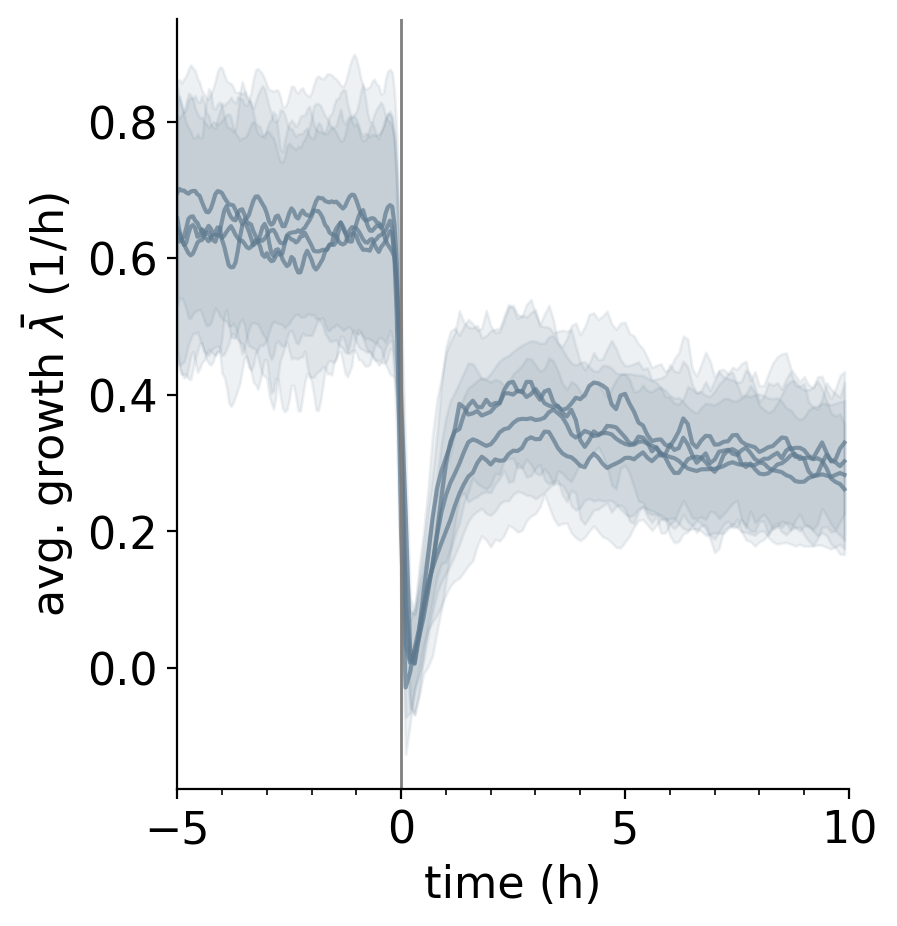

In [14]:
fig, ax = plot_mean_rate_in_time(samples, rate='l',
                                 xlim=[-5, 10], 
                                 show_div=True,
                                 color= "#5e798f",
                                 ylabel=r"avg. growth $\bar{\lambda}$ (1/h)" , 
                                 plot_file=os.path.join("../../figures_for_method_paper/plots_main/carbon_switch", "avg_growth.pdf") )